In [ ]:
# ===== Cell 1: Setup, Libraries, Configuration and Device Detection =====

!pip -q install datasets

import os
import gc
import json
import time
import random
import shutil
import zipfile
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Large_Weights

from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

warnings.filterwarnings("ignore")

# Reproducibility: use the same random seed for repeatable experiments.
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Detect available hardware.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("WOOD TIMBER DEFECT CLASSIFICATION PROJECT")
print("=" * 60)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU unavailable. Running on CPU.")

# All important project settings are maintained here.
CONFIG = {
    "dataset_name": "iluvvatar/wood_surface_defects",
    "split": "train",

    "crop_dir": "/content/wood_crops",
    "output_dir": "/content/wood_project",

    "image_size": 224,
    "crop_padding": 1.3,
    "minimum_crop_side": 128,
    "minimum_box_side": 10,

    "samples_per_class": 800,
    "max_crops_per_source_class": 2,

    "batch_size": 64,
    "num_workers": 2,

    "stage1_epochs": 3,
    "stage2_epochs": 10,
    "patience": 3,

    "stage1_lr": 1e-3,
    "stage2_lr": 1e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.1,

    "seed": SEED,
    "device": DEVICE,

    "class_names": [
        "sound_knot",
        "dead_knot",
        "crack",
        "pin_hole",
        "rot_decay"
    ]
}

os.makedirs(CONFIG["crop_dir"], exist_ok=True)
os.makedirs(CONFIG["output_dir"], exist_ok=True)

print("\nConfiguration loaded successfully.")
print("Target image size:", CONFIG["image_size"])
print("Target crops per class:", CONFIG["samples_per_class"])
print("Total target images:", CONFIG["samples_per_class"] * 5)

WOOD TIMBER DEFECT CLASSIFICATION PROJECT
Device: cuda
GPU: Tesla T4
CUDA version: 13.0

Configuration loaded successfully.
Target image size: 224
Target crops per class: 800
Total target images: 4000


In [ ]:
# ===== Cell 2: Load Hugging Face Dataset in Streaming Mode =====

print("=" * 60)
print("LOADING WOOD SURFACE DEFECT DATASET")
print("=" * 60)

try:
    # Streaming prevents downloading the complete dataset.
    stream_dataset = load_dataset(
        CONFIG["dataset_name"],
        split=CONFIG["split"],
        streaming=True
    )

    print("\nDataset loaded in streaming mode.")

    print("\nDataset features:")
    print(stream_dataset.features)

    # Inspect the first approximately 500 rows.
    label_counter = Counter()
    rows_scanned = 0

    print("\nScanning first 500 rows for label verification...")

    for row in tqdm(stream_dataset.take(500), total=500):

        rows_scanned += 1

        for obj in row.get("objects", []) or []:
            label = str(obj.get("label", "")).strip().lower()
            label_counter[label] += 1

    print("\nRows scanned:", rows_scanned)

    print("\nRaw normalized label counts:")
    for label, count in label_counter.most_common():
        print(f"{label:25s}: {count}")

    print("\nDataset inspection completed.")

except Exception as e:
    raise RuntimeError(
        "Dataset streaming failed. Check your internet connection "
        "and try running this cell again.\n"
        f"Original error: {e}"
    )

LOADING WOOD SURFACE DEFECT DATASET


README.md:   0%|          | 0.00/906 [00:00<?, ?B/s]


Dataset loaded in streaming mode.

Dataset features:
{'id': Value('int64'), 'image': Image(mode=None, decode=True), 'objects': List({'bb': List(Value('float64')), 'label': Value('string')})}

Scanning first 500 rows for label verification...


  0%|          | 0/500 [00:00<?, ?it/s]


Rows scanned: 500

Raw normalized label counts:
live_knot                : 536
dead_knot                : 276
resin                    : 72
knot_with_crack          : 65
crack                    : 46
marrow                   : 35
quartzity                : 23
knot_missing             : 12
blue_stain               : 1

Dataset inspection completed.


In [ ]:
# ===== Cell 3: Define Target Classes and Label Normalization =====

print("=" * 60)
print("TARGET CLASS MAPPING")
print("=" * 60)

# Original dataset label -> project classification label.
CLASS_MAPPING = {
    "live_knot": "sound_knot",
    "dead_knot": "dead_knot",
    "crack": "crack",
    "knot_missing": "pin_hole",
    "blue_stain": "rot_decay"
}

CLASS_NAMES = CONFIG["class_names"]

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

INDEX_TO_CLASS = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}

def normalize_label(label):
    """
    Normalize labels because the dataset contains inconsistent spelling
    and capitalization.
    """
    return str(label).strip().lower()

print("\nOriginal dataset label -> Target class")

for original, target in CLASS_MAPPING.items():
    print(f"{original:20s} -> {target}")

print("\nClass indices:")

for name, index in CLASS_TO_INDEX.items():
    print(f"{name:20s}: {index}")

print("\nIgnored labels:")
print("quartzity, resin, marrow, knot_with_crack, overgrown")

TARGET CLASS MAPPING

Original dataset label -> Target class
live_knot            -> sound_knot
dead_knot            -> dead_knot
crack                -> crack
knot_missing         -> pin_hole
blue_stain           -> rot_decay

Class indices:
sound_knot          : 0
dead_knot           : 1
crack               : 2
pin_hole            : 3
rot_decay           : 4

Ignored labels:
quartzity, resin, marrow, knot_with_crack, overgrown


In [ ]:
# ===== Cell 4: Build the Balanced Crop Dataset =====

print("=" * 60)
print("BUILDING BALANCED CROP DATASET")
print("=" * 60)

# Create one directory per target class.
for class_name in CLASS_NAMES:
    os.makedirs(
        os.path.join(CONFIG["crop_dir"], class_name),
        exist_ok=True
    )

crop_counts = Counter()
source_class_counts = defaultdict(Counter)

target_count = CONFIG["samples_per_class"]

def create_square_crop(image, bbox):
    """
    Convert YOLO normalized coordinates into a padded square crop.

    YOLO format:
    [x_center, y_center, width, height]
    """

    image_width, image_height = image.size

    xc, yc, bw, bh = map(float, bbox)

    # Convert normalized coordinates to pixel coordinates.
    box_width = bw * image_width
    box_height = bh * image_height

    # Ignore extremely small boxes.
    if box_width < CONFIG["minimum_box_side"]:
        return None

    if box_height < CONFIG["minimum_box_side"]:
        return None

    center_x = xc * image_width
    center_y = yc * image_height

    # Square crop avoids stretching thin cracks.
    side = max(
        box_width,
        box_height
    ) * CONFIG["crop_padding"]

    side = max(
        side,
        CONFIG["minimum_crop_side"]
    )

    half_side = side / 2

    left = int(round(center_x - half_side))
    top = int(round(center_y - half_side))
    right = int(round(center_x + half_side))
    bottom = int(round(center_y + half_side))

    # Clip crop coordinates to the image borders.
    left = max(0, left)
    top = max(0, top)
    right = min(image_width, right)
    bottom = min(image_height, bottom)

    if right <= left or bottom <= top:
        return None

    crop = image.crop((left, top, right, bottom))

    # Resize all images to the same model input dimensions.
    crop = crop.resize(
        (CONFIG["image_size"], CONFIG["image_size"]),
        Image.Resampling.BILINEAR
    )

    return crop


try:
    crop_stream = load_dataset(
        CONFIG["dataset_name"],
        split=CONFIG["split"],
        streaming=True
    )

    rows_processed = 0
    saved_total = 0

    progress = tqdm(
        desc="Scanning and cropping dataset",
        unit="source images"
    )

    for row in crop_stream:

        rows_processed += 1
        progress.update(1)

        image = row.get("image")
        objects = row.get("objects", []) or []

        if image is None or len(objects) == 0:
            continue

        # Convert to RGB because pretrained ImageNet models expect 3 channels.
        image = image.convert("RGB")

        source_id = row.get("id", rows_processed)

        # Count crops from the same source image and class.
        current_source_counts = Counter()

        for obj in objects:

            raw_label = normalize_label(obj.get("label", ""))

            # Ignore labels outside our five target categories.
            if raw_label not in CLASS_MAPPING:
                continue

            class_name = CLASS_MAPPING[raw_label]

            # Do not collect more than the required class count.
            if crop_counts[class_name] >= target_count:
                continue

            # Maximum two crops per source image per class.
            if current_source_counts[class_name] >= CONFIG[
                "max_crops_per_source_class"
            ]:
                continue

            crop = create_square_crop(
                image,
                obj.get("bb", [])
            )

            if crop is None:
                continue

            # Unique filenames prevent accidental overwriting.
            filename = (
                f"{class_name}_{source_id}_"
                f"{crop_counts[class_name]}.jpg"
            )

            save_path = os.path.join(
                CONFIG["crop_dir"],
                class_name,
                filename
            )

            crop.save(
                save_path,
                format="JPEG",
                quality=95
            )

            crop_counts[class_name] += 1
            current_source_counts[class_name] += 1
            source_class_counts[source_id][class_name] += 1

            saved_total += 1

        # Stop immediately when every class reaches its target.
        if all(
            crop_counts[name] >= target_count
            for name in CLASS_NAMES
        ):
            break

    progress.close()

except Exception as e:
    print("\nDataset streaming or cropping encountered an error.")
    print("Error:", str(e))
    print("Check the internet connection and rerun this cell if necessary.")
    raise

print("\nRows processed:", rows_processed)
print("Total crops saved:", saved_total)

print("\nInitial crop counts:")

for name in CLASS_NAMES:
    print(f"{name:20s}: {crop_counts[name]}")

# Balance all available classes to the smallest available count.
available_classes = [
    name for name in CLASS_NAMES
    if crop_counts[name] > 0
]

if len(available_classes) < 4:
    raise RuntimeError(
        "Fewer than four target classes contain valid crops. "
        "A meaningful classification experiment cannot continue."
    )

balanced_target = min(
    target_count,
    min(crop_counts[name] for name in available_classes)
)

# Remove classes with zero available samples.
if len(available_classes) == 4:
    print("\nWARNING: One target class could not be collected.")
    print("Continuing with four available classes.")

CLASS_NAMES = available_classes

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

INDEX_TO_CLASS = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}

# Delete excess crops so every retained class has exactly the same count.
for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        CONFIG["crop_dir"],
        class_name
    )

    files = sorted(
        Path(class_dir).glob("*.jpg")
    )

    random.Random(SEED).shuffle(files)

    for excess_file in files[balanced_target:]:
        excess_file.unlink()

    crop_counts[class_name] = balanced_target

print("\nFINAL BALANCED DATASET")
print("-" * 40)

for name in CLASS_NAMES:
    print(f"{name:20s}: {crop_counts[name]}")

print("\nTotal balanced images:", sum(crop_counts.values()))

BUILDING BALANCED CROP DATASET


Scanning and cropping dataset: 0source images [00:00, ?source images/s]


Rows processed: 20276
Total crops saved: 2970

Initial crop counts:
sound_knot          : 800
dead_knot           : 800
crack               : 800
pin_hole            : 480
rot_decay           : 90

FINAL BALANCED DATASET
----------------------------------------
sound_knot          : 90
dead_knot           : 90
crack               : 90
pin_hole            : 90
rot_decay           : 90

Total balanced images: 450


DATASET VERIFICATION
sound_knot          : 90 images
dead_knot           : 90 images
crack               : 90 images
pin_hole            : 90 images
rot_decay           : 90 images

Total images: 450
Number of classes: 5
Valid images: 450


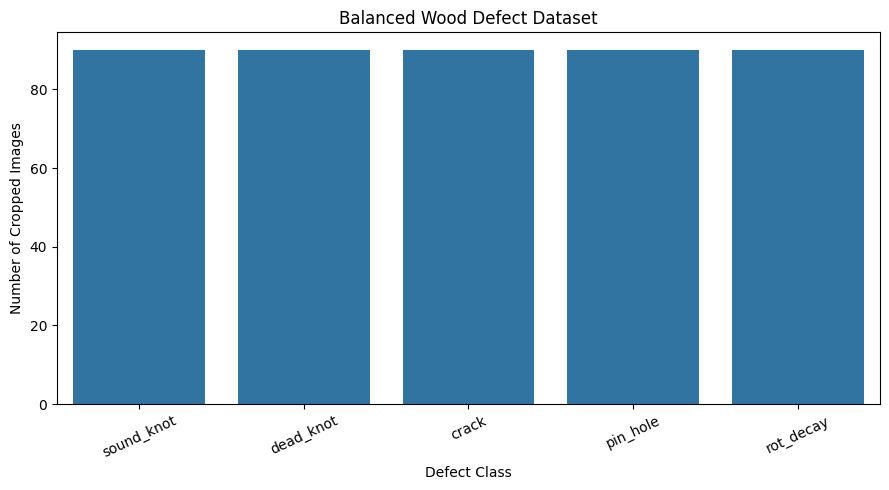

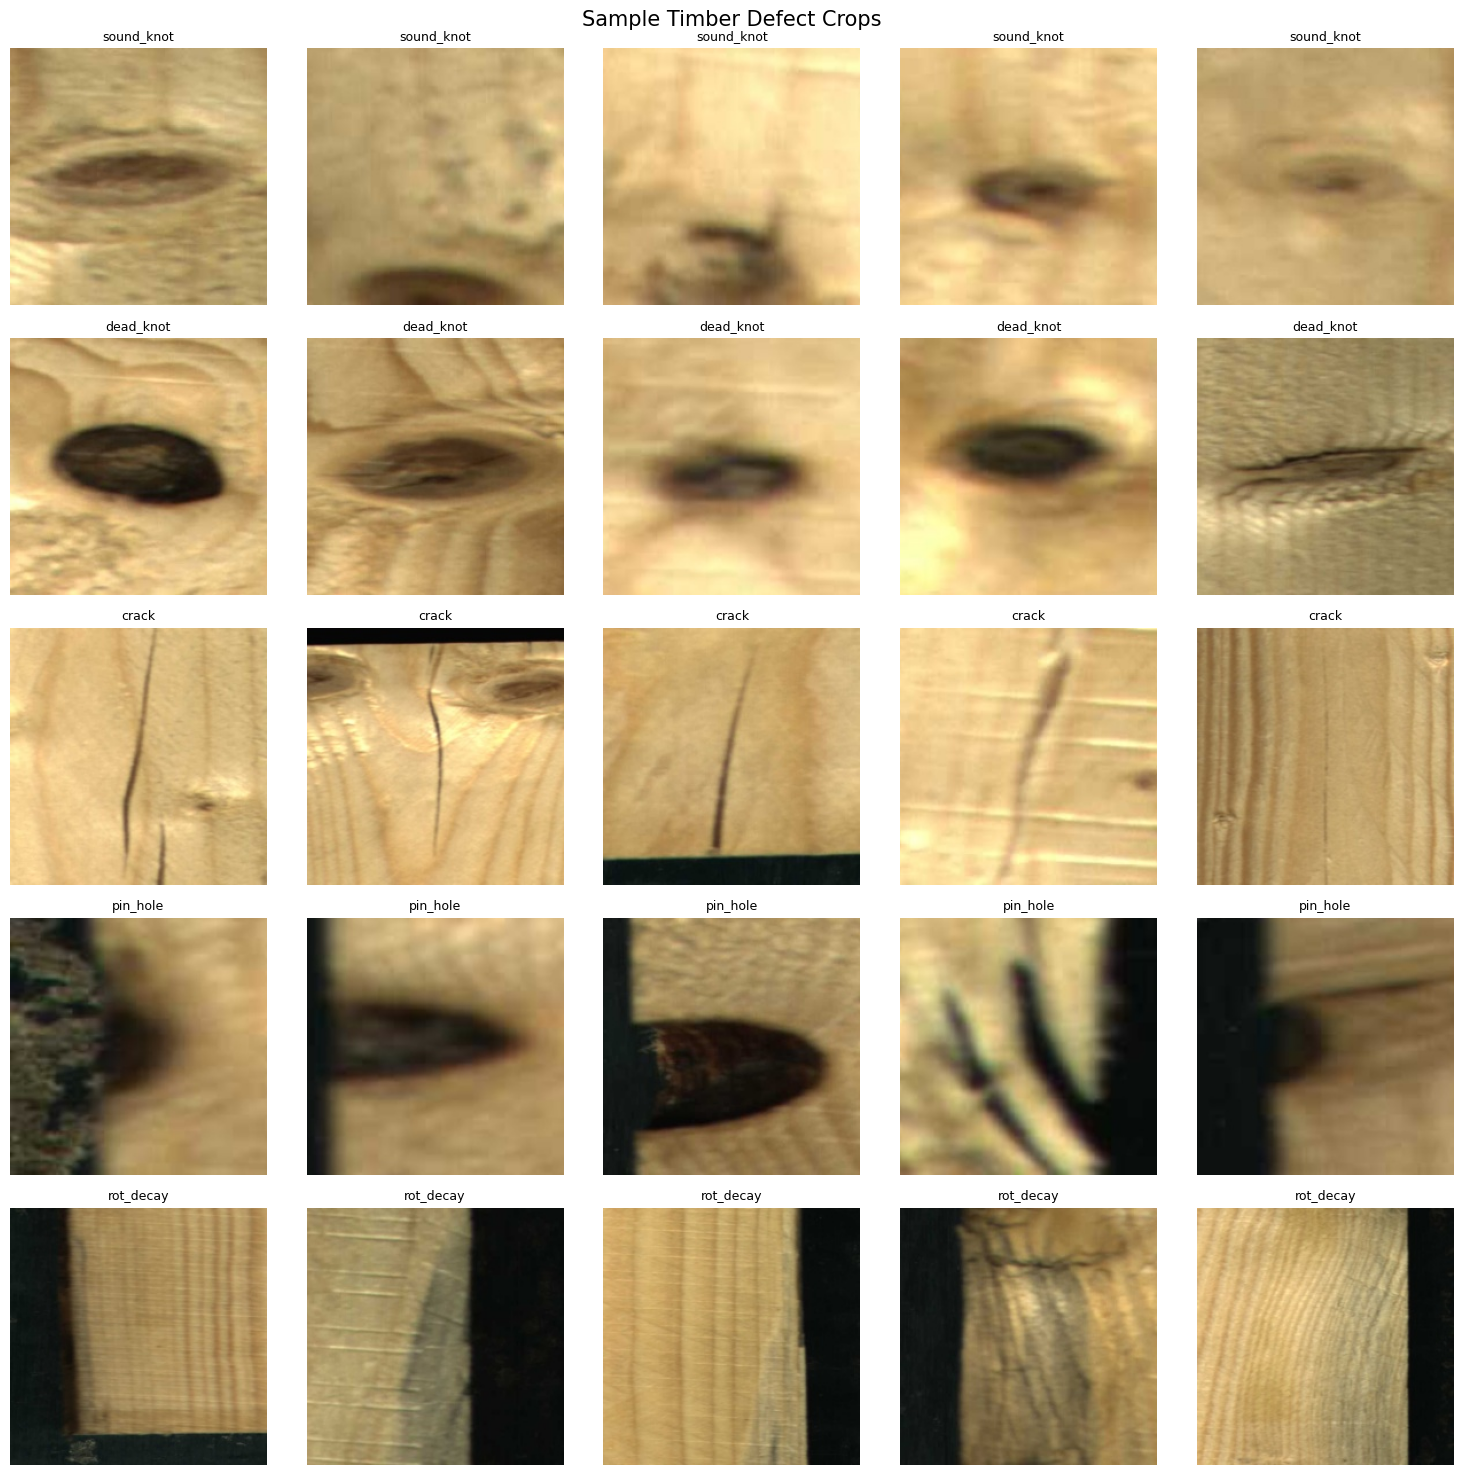

In [ ]:
# ===== Cell 5: Check Dataset and Visualize Sample Crops =====

print("=" * 60)
print("DATASET VERIFICATION")
print("=" * 60)

image_records = []

for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        CONFIG["crop_dir"],
        class_name
    )

    files = sorted(
        Path(class_dir).glob("*.jpg")
    )

    print(f"{class_name:20s}: {len(files)} images")

    for file_path in files:
        image_records.append({
            "image_path": str(file_path),
            "class_name": class_name,
            "label": CLASS_TO_INDEX[class_name]
        })

dataset_df = pd.DataFrame(image_records)

print("\nTotal images:", len(dataset_df))
print("Number of classes:", len(CLASS_NAMES))

# Check that all images are readable.
valid_count = 0

for path in dataset_df["image_path"]:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_count += 1
    except Exception:
        print("Invalid image:", path)

print("Valid images:", valid_count)

# Class distribution.
plt.figure(figsize=(9, 5))

class_counts = dataset_df["class_name"].value_counts().reindex(
    CLASS_NAMES
)

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Balanced Wood Defect Dataset")
plt.xlabel("Defect Class")
plt.ylabel("Number of Cropped Images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Display 5 samples from every class.
fig, axes = plt.subplots(
    len(CLASS_NAMES),
    5,
    figsize=(15, 3 * len(CLASS_NAMES))
)

if len(CLASS_NAMES) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_index, class_name in enumerate(CLASS_NAMES):

    samples = dataset_df[
        dataset_df["class_name"] == class_name
    ].sample(
        n=min(5, class_counts[class_name]),
        random_state=SEED
    )

    for col_index in range(5):

        ax = axes[row_index, col_index]

        if col_index < len(samples):

            image_path = samples.iloc[col_index]["image_path"]

            img = Image.open(image_path).convert("RGB")

            ax.imshow(img)
            ax.set_title(class_name, fontsize=9)

        ax.axis("off")

plt.suptitle(
    "Sample Timber Defect Crops",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
# ===== Cell 6: Stratified Train Validation Test Split =====

print("=" * 60)
print("CREATING DATASET SPLITS")
print("=" * 60)

# First, separate 15% for final testing.
train_val_df, test_df = train_test_split(
    dataset_df,
    test_size=0.15,
    random_state=SEED,
    stratify=dataset_df["label"]
)

# Divide remaining 85% into 70% train and 15% validation.
# 0.17647 of 85% gives approximately 15% of the complete dataset.
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.1764705882,
    random_state=SEED,
    stratify=train_val_df["label"]
)

# Assign split names.
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# Combine all records into one DataFrame.
split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Save split information for reproducibility.
split_path = os.path.join(
    CONFIG["output_dir"],
    "split.csv"
)

split_df.to_csv(
    split_path,
    index=False
)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total images:", len(split_df))

print("\nSplit distribution by class:")

split_summary = pd.crosstab(
    split_df["class_name"],
    split_df["split"]
)

print(split_summary)

print("\nSaved split file:", split_path)

CREATING DATASET SPLITS
Train images: 314
Validation images: 68
Test images: 68
Total images: 450

Split distribution by class:
split       test  train  validation
class_name                         
crack         14     63          13
dead_knot     13     63          14
pin_hole      14     62          14
rot_decay     13     63          14
sound_knot    14     63          13

Saved split file: /content/wood_project/split.csv


In [ ]:
# ===== Cell 7: Define Transforms, Dataset and DataLoaders =====

print("=" * 60)
print("PREPARING PYTORCH DATALOADERS")
print("=" * 60)

# ImageNet normalization is required for pretrained MobileNet weights.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training augmentation helps the model handle different board orientations
# and small lighting and color variations.
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Validation and testing must remain unchanged.
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


class WoodDefectDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        record = self.dataframe.iloc[index]

        image_path = record["image_path"]
        label = int(record["label"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create individual datasets.
train_dataset = WoodDefectDataset(
    train_df,
    train_transform
)

val_dataset = WoodDefectDataset(
    val_df,
    eval_transform
)

test_dataset = WoodDefectDataset(
    test_df,
    eval_transform
)

# Separate generators improve reproducibility.
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

# Create DataLoaders.
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# Verify one batch before training.
images, labels = next(iter(train_loader))

print("\nSample batch shape:", images.shape)
print("Sample labels shape:", labels.shape)
print("Number of classes:", len(CLASS_NAMES))

PREPARING PYTORCH DATALOADERS
Training batches: 5
Validation batches: 2
Testing batches: 2

Sample batch shape: torch.Size([64, 3, 224, 224])
Sample labels shape: torch.Size([64])
Number of classes: 5


In [ ]:
# ===== Cell 8: Build MobileNetV3-Large Model =====

print("=" * 60)
print("BUILDING MOBILENETV3-LARGE")
print("=" * 60)

try:
    # Load pretrained ImageNet weights.
    weights = MobileNet_V3_Large_Weights.DEFAULT

    model = models.mobilenet_v3_large(
        weights=weights
    )

except Exception as e:
    raise RuntimeError(
        "Unable to download pretrained MobileNetV3 weights. "
        "Check your internet connection and rerun this cell.\n"
        f"Error: {e}"
    )

# Get the number of input features in the original classifier.
input_features = model.classifier[-1].in_features

# Replace the final layer with our project classes.
model.classifier[-1] = nn.Linear(
    input_features,
    len(CLASS_NAMES)
)

model = model.to(DEVICE)

# Count parameters.
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Estimate model size using float32 parameters.
model_size_mb = (
    sum(
        parameter.numel() * parameter.element_size()
        for parameter in model.parameters()
    ) / (1024 ** 2)
)

print("Model: MobileNetV3-Large")
print("Number of output classes:", len(CLASS_NAMES))
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Estimated parameter size:", f"{model_size_mb:.2f} MB")

print("\nModel architecture:")
print(model.classifier)

BUILDING MOBILENETV3-LARGE
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 158MB/s]


Model: MobileNetV3-Large
Number of output classes: 5
Total parameters: 4,208,437
Trainable parameters: 4,208,437
Estimated parameter size: 16.05 MB

Model architecture:
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=5, bias=True)
)


In [ ]:
# ===== Cell 9: Training and Evaluation Helper Functions =====

print("=" * 60)
print("DEFINING TRAINING FUNCTIONS")
print("=" * 60)

criterion = nn.CrossEntropyLoss(
    label_smoothing=CONFIG["label_smoothing"]
)

# Mixed precision reduces GPU memory consumption.
use_amp = torch.cuda.is_available()

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


def train_one_epoch(model, loader, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=use_amp):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        # Scale gradients when mixed precision is enabled.
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="Evaluating",
        leave=False
    ):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.cuda.amp.autocast(enabled=use_amp):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


class EarlyStopping:

    def __init__(self, patience=3):

        self.patience = patience
        self.best_accuracy = -1
        self.counter = 0

    def step(self, current_accuracy):

        if current_accuracy > self.best_accuracy:

            self.best_accuracy = current_accuracy
            self.counter = 0

            return False, True

        self.counter += 1

        should_stop = self.counter >= self.patience

        return should_stop, False


# Training history is shared between both stages.
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = -1.0

best_model_path = os.path.join(
    CONFIG["output_dir"],
    "best_model.pth"
)

print("Training helpers defined successfully.")
print("Mixed precision enabled:", use_amp)
print("Early stopping patience:", CONFIG["patience"])

DEFINING TRAINING FUNCTIONS
Training helpers defined successfully.
Mixed precision enabled: True
Early stopping patience: 3


In [ ]:
# ===== Cell 10: Stage 1 Training - Frozen Backbone =====

print("=" * 60)
print("STAGE 1: TRAINING CLASSIFICATION HEAD")
print("=" * 60)

# Freeze all backbone parameters.
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze only the final classification layer.
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

# Optimizer only receives trainable parameters.
optimizer_stage1 = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=CONFIG["stage1_lr"],
    weight_decay=CONFIG["weight_decay"]
)

scheduler_stage1 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_stage1,
    T_max=CONFIG["stage1_epochs"]
)

for epoch in range(CONFIG["stage1_epochs"]):

    print(f"\nStage 1 - Epoch {epoch + 1}/{CONFIG['stage1_epochs']}")

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer_stage1
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader
    )

    scheduler_stage1.step()

    # Save the best model based on validation accuracy.
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print("New best model saved.")

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy * 100:.2f}%"
    )

print("\nStage 1 completed.")
print("Best validation accuracy:", f"{best_val_accuracy * 100:.2f}%")

STAGE 1: TRAINING CLASSIFICATION HEAD

Stage 1 - Epoch 1/3


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

New best model saved.
Train Loss: 1.3609 | Train Accuracy: 50.64%
Val Loss: 1.3352 | Val Accuracy: 44.12%

Stage 1 - Epoch 2/3


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

... (2 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f5ec31d6700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f5ec31d6700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

<function _MultiProcessingDataLoaderIter.__del__ at 0x7f5ec31d6700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f5ec31d6700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiproces

Train Loss: 0.9041 | Train Accuracy: 74.84%
Val Loss: 1.2295 | Val Accuracy: 39.71%

Stage 1 completed.
Best validation accuracy: 44.12%


In [ ]:
# ===== Cell 11: Stage 2 Training - Full Network Fine-Tuning =====

print("=" * 60)
print("STAGE 2: FULL NETWORK FINE-TUNING")
print("=" * 60)

# Unfreeze the entire model.
for parameter in model.parameters():
    parameter.requires_grad = True

optimizer_stage2 = optim.AdamW(
    model.parameters(),
    lr=CONFIG["stage2_lr"],
    weight_decay=CONFIG["weight_decay"]
)

scheduler_stage2 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_stage2,
    T_max=CONFIG["stage2_epochs"]
)

early_stopping = EarlyStopping(
    patience=CONFIG["patience"]
)

# Continue from the best validation accuracy obtained in Stage 1.
early_stopping.best_accuracy = best_val_accuracy

for epoch in range(CONFIG["stage2_epochs"]):

    print(
        f"\nStage 2 - Epoch "
        f"{epoch + 1}/{CONFIG['stage2_epochs']}"
    )

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer_stage2
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader
    )

    scheduler_stage2.step()

    # Save only when validation accuracy improves.
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print("Best model checkpoint updated.")

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy * 100:.2f}%"
    )

    print(
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy * 100:.2f}%"
    )

    print(
        "Learning Rate:",
        optimizer_stage2.param_groups[0]["lr"]
    )

    stop, improved = early_stopping.step(val_accuracy)

    if stop:
        print("\nEarly stopping activated.")
        print("Validation accuracy did not improve.")
        break

print("\nStage 2 completed.")
print("Best validation accuracy:", f"{best_val_accuracy * 100:.2f}%")
print("Best checkpoint:", best_model_path)

STAGE 2: FULL NETWORK FINE-TUNING

Stage 2 - Epoch 1/10


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Best model checkpoint updated.
Train Loss: 0.8374 | Train Accuracy: 75.48%
Validation Loss: 1.1014 | Validation Accuracy: 52.94%
Learning Rate: 9.755282581475769e-05

Stage 2 - Epoch 2/10


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

... (24 outputs left out)

Best model checkpoint updated.
Train Loss: 0.5843 | Train Accuracy: 92.04%
Validation Loss: 0.8910 | Validation Accuracy: 70.59%
Learning Rate: 2.447174185242323e-06

Stage 2 - Epoch 10/10


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Best model checkpoint updated.
Train Loss: 0.5726 | Train Accuracy: 93.63%
Validation Loss: 0.8829 | Validation Accuracy: 73.53%
Learning Rate: 0.0

Stage 2 completed.
Best validation accuracy: 73.53%
Best checkpoint: /content/wood_project/best_model.pth


TRAINING PERFORMANCE VISUALIZATION


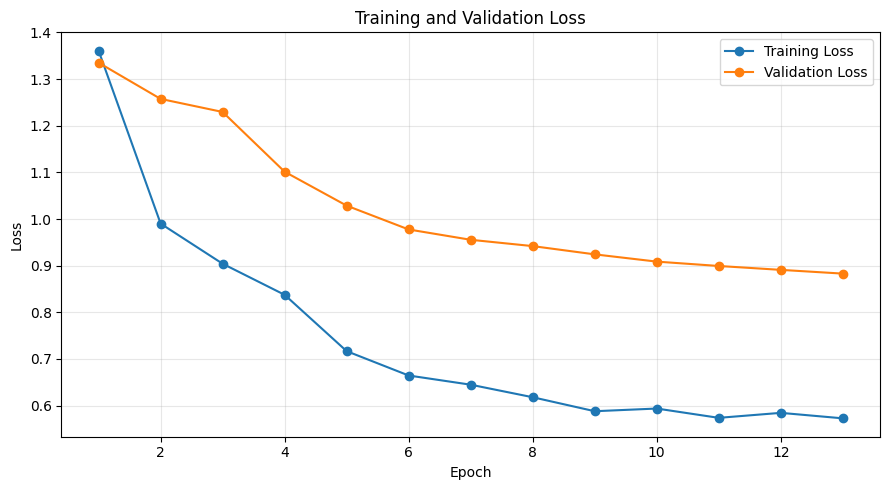

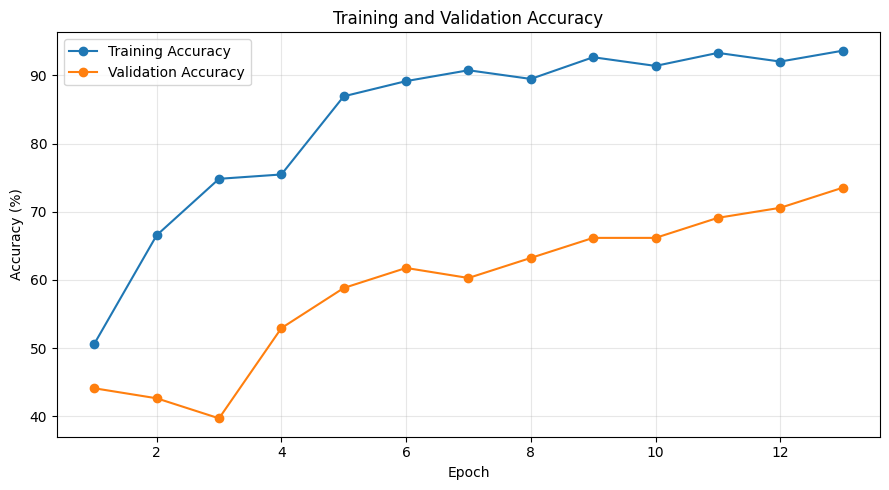


Total training epochs: 13
Best validation accuracy: 73.53%


In [ ]:
# ===== Cell 12: Plot Training and Validation Curves =====

print("=" * 60)
print("TRAINING PERFORMANCE VISUALIZATION")
print("=" * 60)

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

# Loss curves.
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Accuracy curves.
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTotal training epochs:", len(history["train_loss"]))
print("Best validation accuracy:", f"{best_val_accuracy * 100:.2f}%")

In [ ]:
# ===== Cell 13: Evaluate Best Model on Test Dataset =====

print("=" * 60)
print("FINAL TEST DATASET EVALUATION")
print("=" * 60)

# Load the checkpoint with the highest validation accuracy.
checkpoint = torch.load(
    best_model_path,
    map_location=DEVICE
)

model.load_state_dict(checkpoint)
model.to(DEVICE)
model.eval()

all_predictions = []
all_targets = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Testing"
    ):

        images = images.to(DEVICE)

        with torch.cuda.amp.autocast(enabled=use_amp):

            outputs = model(images)

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )

        predictions = probabilities.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            labels.numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)
all_probabilities = np.array(all_probabilities)

# Calculate overall accuracy.
test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

weighted_f1 = f1_score(
    all_targets,
    all_predictions,
    average="weighted"
)

print("\nTEST ACCURACY:")
print(f"{test_accuracy * 100:.2f}%")

print("\nMACRO F1-SCORE:")
print(f"{macro_f1:.4f}")

print("\nWEIGHTED F1-SCORE:")
print(f"{weighted_f1:.4f}")

# Detailed per-class evaluation.
report = classification_report(
    all_targets,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
)

print("\nCLASSIFICATION REPORT:")
print(report)

# Save report information for final results.
report_dict = classification_report(
    all_targets,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print("Test evaluation completed.")

FINAL TEST DATASET EVALUATION


Testing:   0%|          | 0/2 [00:00<?, ?it/s]


TEST ACCURACY:
72.06%

MACRO F1-SCORE:
0.7205

WEIGHTED F1-SCORE:
0.7220

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  sound_knot       0.67      0.86      0.75        14
   dead_knot       0.62      0.62      0.62        13
       crack       1.00      0.57      0.73        14
    pin_hole       1.00      0.64      0.78        14
   rot_decay       0.60      0.92      0.73        13

    accuracy                           0.72        68
   macro avg       0.78      0.72      0.72        68
weighted avg       0.78      0.72      0.72        68

Test evaluation completed.


CONFUSION MATRIX ANALYSIS


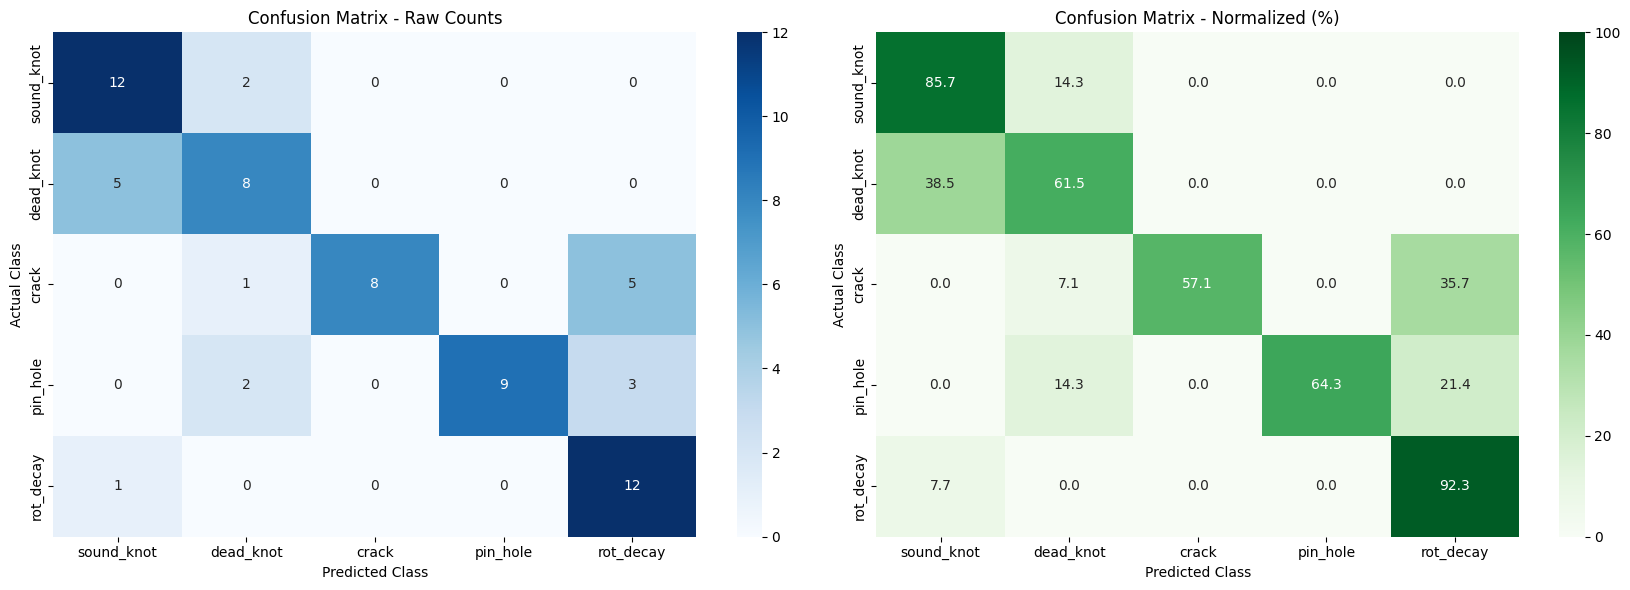


Confusion matrix values:
[[12  2  0  0  0]
 [ 5  8  0  0  0]
 [ 0  1  8  0  5]
 [ 0  2  0  9  3]
 [ 1  0  0  0 12]]


In [ ]:
# ===== Cell 14: Plot Confusion Matrices =====

print("=" * 60)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 60)

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(len(CLASS_NAMES)))
)

# Row normalization converts counts into percentages.
cm_normalized = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 6)
)

# Raw counts.
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix - Raw Counts")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Normalized percentages.
sns.heatmap(
    cm_normalized * 100,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    vmin=0,
    vmax=100,
    ax=axes[1]
)

axes[1].set_title("Confusion Matrix - Normalized (%)")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("\nConfusion matrix values:")
print(cm)

MISCLASSIFICATION ANALYSIS
Total test images: 68
Incorrect predictions: 19


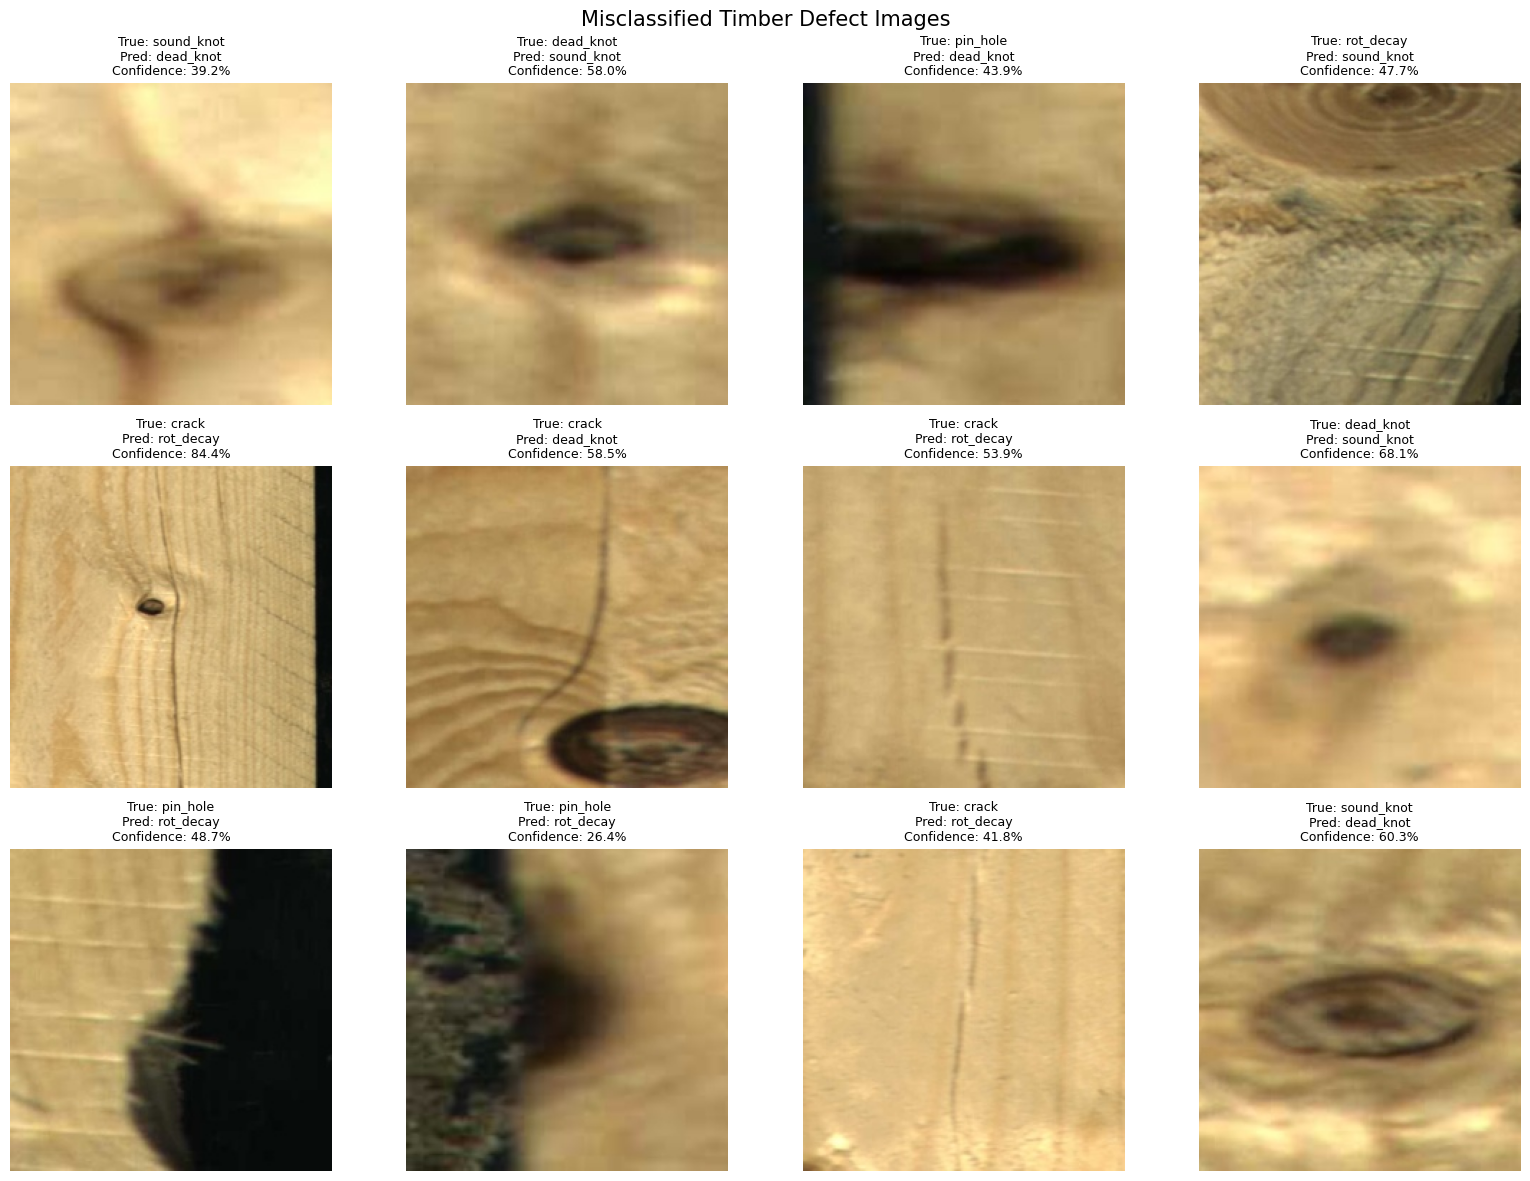


Most frequently confused class pairs:
dead_knot -> sound_knot: 5
crack -> rot_decay: 5
pin_hole -> rot_decay: 3
sound_knot -> dead_knot: 2
pin_hole -> dead_knot: 2


In [ ]:
# ===== Cell 15: Visualize Misclassified Test Images =====

print("=" * 60)
print("MISCLASSIFICATION ANALYSIS")
print("=" * 60)

misclassified_indices = np.where(
    all_targets != all_predictions
)[0]

print("Total test images:", len(all_targets))
print("Incorrect predictions:", len(misclassified_indices))

if len(misclassified_indices) == 0:

    print("\nNo misclassified images found!")

else:

    # Select up to 12 incorrect predictions.
    selected_indices = misclassified_indices[:12]

    columns = 4
    rows = int(np.ceil(len(selected_indices) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 4 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for plot_index, sample_index in enumerate(selected_indices):

        ax = axes[plot_index]

        image_path = test_df.iloc[sample_index]["image_path"]

        image = Image.open(image_path).convert("RGB")

        true_class = INDEX_TO_CLASS[
            int(all_targets[sample_index])
        ]

        predicted_class = INDEX_TO_CLASS[
            int(all_predictions[sample_index])
        ]

        confidence = all_probabilities[
            sample_index
        ][all_predictions[sample_index]]

        ax.imshow(image)

        ax.set_title(
            f"True: {true_class}\n"
            f"Pred: {predicted_class}\n"
            f"Confidence: {confidence * 100:.1f}%",
            fontsize=9
        )

        ax.axis("off")

    # Hide unused subplot positions.
    for index in range(len(selected_indices), len(axes)):
        axes[index].axis("off")

    plt.suptitle(
        "Misclassified Timber Defect Images",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

    # Find the most frequently confused class pairs.
    confusion_pairs = Counter()

    for index in misclassified_indices:

        true_class = INDEX_TO_CLASS[
            int(all_targets[index])
        ]

        predicted_class = INDEX_TO_CLASS[
            int(all_predictions[index])
        ]

        confusion_pairs[
            (true_class, predicted_class)
        ] += 1

    print("\nMost frequently confused class pairs:")

    for (true_class, predicted_class), count in confusion_pairs.most_common(5):

        print(
            f"{true_class} -> {predicted_class}: {count}"
        )

# Why these errors may happen:
# 1. Dead knots, sound knots and cracks can share similar wood-grain textures.
# 2. Small defects, lighting differences and surrounding wood patterns can make boundaries difficult to distinguish.

In [ ]:
# ===== Cell 16: GPU and CPU Inference Benchmark =====

print("=" * 60)
print("INFERENCE SPEED BENCHMARK")
print("=" * 60)

WARMUP_RUNS = 20
TIMED_RUNS = 200

benchmark_input = torch.randn(
    1,
    3,
    224,
    224
)

def benchmark_inference(model, device):

    model = model.to(device)
    model.eval()

    sample = benchmark_input.to(device)

    # Warm-up allows the device to initialize execution.
    with torch.inference_mode():

        for _ in range(WARMUP_RUNS):
            _ = model(sample)

    if device.type == "cuda":
        torch.cuda.synchronize()

    latencies = []

    with torch.inference_mode():

        for _ in tqdm(
            range(TIMED_RUNS),
            desc=f"Benchmarking {device.type}"
        ):

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            _ = model(sample)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end = time.perf_counter()

            latencies.append(
                (end - start) * 1000
            )

    mean_latency = float(np.mean(latencies))
    p95_latency = float(np.percentile(latencies, 95))

    fps = 1000.0 / mean_latency

    return {
        "mean_latency_ms": mean_latency,
        "p95_latency_ms": p95_latency,
        "fps": fps
    }


# GPU benchmark.
if torch.cuda.is_available():

    gpu_results = benchmark_inference(
        model,
        torch.device("cuda")
    )

else:

    gpu_results = {
        "mean_latency_ms": None,
        "p95_latency_ms": None,
        "fps": None
    }

    print("\nGPU unavailable. GPU benchmark skipped.")

# CPU benchmark.
cpu_results = benchmark_inference(
    model,
    torch.device("cpu")
)

# Restore model to the original device.
model = model.to(DEVICE)

print("\nGPU RESULTS")

for key, value in gpu_results.items():
    print(f"{key}: {value}")

print("\nCPU RESULTS")

for key, value in cpu_results.items():
    print(f"{key}: {value:.4f}")

# Model size.
model_size_mb = (
    os.path.getsize(best_model_path) / (1024 ** 2)
)

print("\nSaved checkpoint size:", f"{model_size_mb:.2f} MB")

INFERENCE SPEED BENCHMARK


Benchmarking cuda:   0%|          | 0/200 [00:00<?, ?it/s]

Benchmarking cpu:   0%|          | 0/200 [00:00<?, ?it/s]


GPU RESULTS
mean_latency_ms: 6.409181400008492
p95_latency_ms: 9.510172800173676
fps: 156.0261658374461

CPU RESULTS
mean_latency_ms: 26.6463
p95_latency_ms: 35.6962
fps: 37.5287

Saved checkpoint size: 16.25 MB


In [ ]:
# ===== Cell 17: Conveyor Sorting Simulation =====

print("=" * 60)
print("AUTOMATED CONVEYOR SORTING SIMULATION")
print("=" * 60)

SORTING_RULES = {
    "sound_knot": "Grade A",
    "dead_knot": "Grade B",
    "crack": "Reject",
    "pin_hole": "Reject",
    "rot_decay": "Reject"
}

CONFIDENCE_THRESHOLD = 0.70

# Select 100 random test samples.
simulation_count = min(
    100,
    len(test_df)
)

simulation_df = test_df.sample(
    n=simulation_count,
    random_state=SEED
).reset_index(drop=True)

bin_counts = Counter()

simulation_results = []

model.eval()

start_simulation = time.perf_counter()

with torch.inference_mode():

    for _, record in tqdm(
        simulation_df.iterrows(),
        total=len(simulation_df),
        desc="Sorting timber boards"
    ):

        image = Image.open(
            record["image_path"]
        ).convert("RGB")

        input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

        with torch.cuda.amp.autocast(enabled=use_amp):

            output = model(input_tensor)

        probabilities = torch.softmax(
            output.float(),
            dim=1
        )

        confidence, predicted_index = probabilities.max(dim=1)

        confidence = confidence.item()

        predicted_class = INDEX_TO_CLASS[
            predicted_index.item()
        ]

        # Low-confidence predictions are sent for manual inspection.
        if confidence < CONFIDENCE_THRESHOLD:

            destination = "Manual Review"

        else:

            destination = SORTING_RULES[predicted_class]

        bin_counts[destination] += 1

        simulation_results.append({
            "image_path": record["image_path"],
            "true_class": record["class_name"],
            "predicted_class": predicted_class,
            "confidence": confidence,
            "destination": destination
        })

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

simulation_time = time.perf_counter() - start_simulation

throughput = simulation_count / simulation_time

simulation_results_df = pd.DataFrame(
    simulation_results
)

print("\nSORTING BIN SUMMARY")
print("-" * 45)

sorting_summary = pd.DataFrame(
    [
        {
            "Sorting Bin": name,
            "Number of Boards": bin_counts[name]
        }
        for name in [
            "Grade A",
            "Grade B",
            "Reject",
            "Manual Review"
        ]
    ]
)

print(sorting_summary.to_string(index=False))

print("\nTotal boards processed:", simulation_count)
print("Simulation time:", f"{simulation_time:.4f} seconds")
print("Simulated throughput:", f"{throughput:.2f} boards/second")

print("\nFirst 10 sorting decisions:")
print(
    simulation_results_df[
        ["true_class", "predicted_class", "confidence", "destination"]
    ].head(10).to_string(index=False)
)

AUTOMATED CONVEYOR SORTING SIMULATION


Sorting timber boards:   0%|          | 0/68 [00:00<?, ?it/s]


SORTING BIN SUMMARY
---------------------------------------------
  Sorting Bin  Number of Boards
      Grade A                 5
      Grade B                 4
       Reject                19
Manual Review                40

Total boards processed: 68
Simulation time: 1.0019 seconds
Simulated throughput: 67.87 boards/second

First 10 sorting decisions:
true_class predicted_class  confidence   destination
 dead_knot       dead_knot    0.339307 Manual Review
sound_knot      sound_knot    0.439622 Manual Review
     crack       rot_decay    0.844052        Reject
     crack           crack    0.809687        Reject
  pin_hole       rot_decay    0.486357 Manual Review
     crack       rot_decay    0.532218 Manual Review
  pin_hole        pin_hole    0.551873 Manual Review
  pin_hole        pin_hole    0.426844 Manual Review
 dead_knot       dead_knot    0.436481 Manual Review
     crack       rot_decay    0.540448 Manual Review


In [ ]:
# ===== Cell 18: Export Model to TorchScript and ONNX =====

print("=" * 60)
print("MODEL EXPORT")
print("=" * 60)

export_dir = CONFIG["output_dir"]

model.eval()
model = model.to(DEVICE)

dummy_input = torch.randn(
    1,
    3,
    224,
    224,
    device=DEVICE
)

# -----------------------------
# 1. TorchScript Export
# -----------------------------

torchscript_path = os.path.join(
    export_dir,
    "wood_mobilenetv3_torchscript.pt"
)

try:

    traced_model = torch.jit.trace(
        model,
        dummy_input
    )

    traced_model = traced_model.to("cpu")
    traced_model.save(torchscript_path)

    print("TorchScript exported successfully.")

    print(
        "TorchScript size:",
        f"{os.path.getsize(torchscript_path) / (1024 ** 2):.2f} MB"
    )

except Exception as e:

    print("TorchScript export failed:", str(e))


# -----------------------------
# 2. ONNX Export
# -----------------------------

onnx_path = os.path.join(
    export_dir,
    "wood_mobilenetv3.onnx"
)

onnx_export_success = False

try:

    # ONNX export uses a CPU copy for portability.
    cpu_model = model.to("cpu").eval()

    cpu_dummy = torch.randn(
        1,
        3,
        224,
        224
    )

    torch.onnx.export(
        cpu_model,
        cpu_dummy,
        onnx_path,
        export_params=True,
        opset_version=17,
        do_constant_folding=True,
        input_names=["input"],
        output_names=["output"],
        dynamic_axes={
            "input": {
                0: "batch_size"
            },
            "output": {
                0: "batch_size"
            }
        }
    )

    onnx_export_success = True

    print("\nONNX exported successfully.")

    print(
        "ONNX size:",
        f"{os.path.getsize(onnx_path) / (1024 ** 2):.2f} MB"
    )

except Exception as e:

    print("\nONNX export failed or dependency unavailable.")
    print("Error:", str(e))

finally:

    model = model.to(DEVICE)


# -----------------------------
# 3. Optional ONNX Runtime
# -----------------------------

if onnx_export_success:

    try:

        !pip -q install onnx onnxruntime

        import onnxruntime as ort

        session = ort.InferenceSession(
            onnx_path,
            providers=["CPUExecutionProvider"]
        )

        input_name = session.get_inputs()[0].name

        onnx_input = np.random.randn(
            1,
            3,
            224,
            224
        ).astype(np.float32)

        # Warm-up.
        for _ in range(20):
            session.run(
                None,
                {input_name: onnx_input}
            )

        onnx_latencies = []

        for _ in range(200):

            start = time.perf_counter()

            session.run(
                None,
                {input_name: onnx_input}
            )

            end = time.perf_counter()

            onnx_latencies.append(
                (end - start) * 1000
            )

        print("\nONNX RUNTIME CPU BENCHMARK")
        print(
            "Mean latency:",
            f"{np.mean(onnx_latencies):.3f} ms"
        )

        print(
            "P95 latency:",
            f"{np.percentile(onnx_latencies, 95):.3f} ms"
        )

        print(
            "FPS:",
            f"{1000 / np.mean(onnx_latencies):.2f}"
        )

    except Exception as e:

        print("\nONNX Runtime unavailable.")
        print("Skipping ONNX benchmark:", str(e))

print("\nModel export stage completed.")

MODEL EXPORT
TorchScript exported successfully.
TorchScript size: 16.66 MB

ONNX export failed or dependency unavailable.
Error: No module named 'onnxscript'

Model export stage completed.


END-TO-END PREDICTION SYSTEM

DEMO: THREE TEST IMAGES

DEMO IMAGE 1


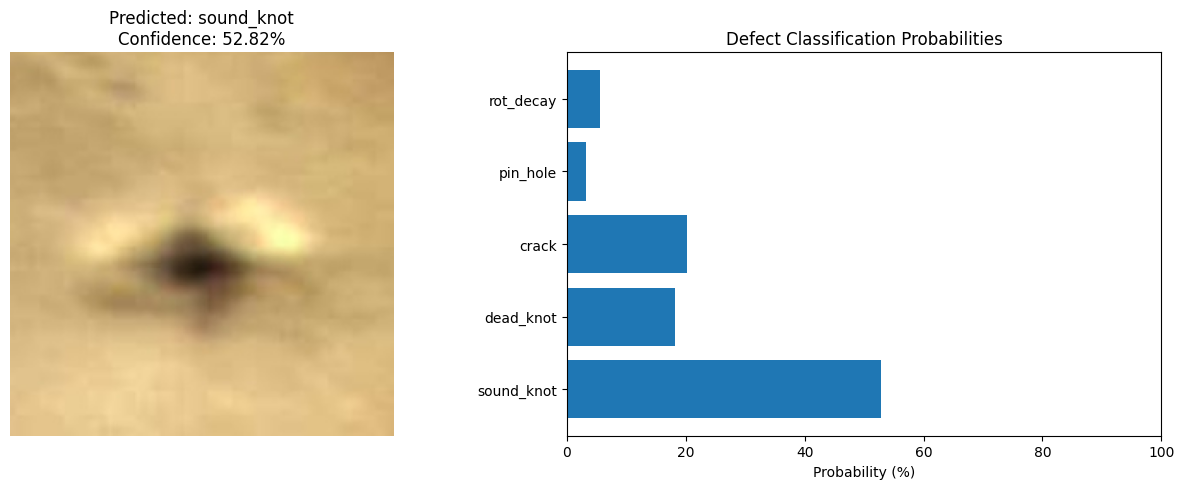


PREDICTION RESULT
----------------------------------------
Predicted class: sound_knot
Confidence: 52.82%
Sorting decision: Manual Review

DEMO IMAGE 2


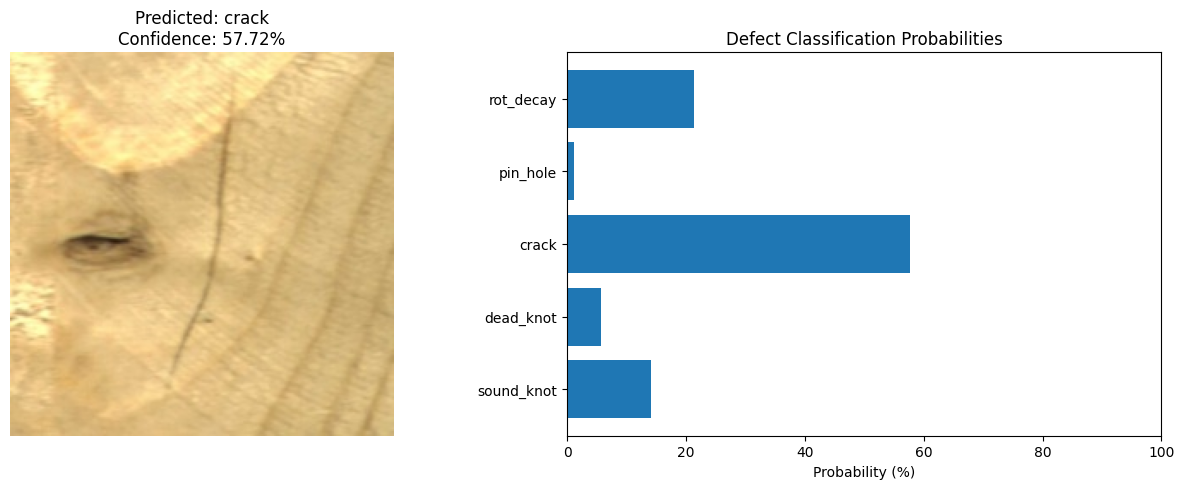


PREDICTION RESULT
----------------------------------------
Predicted class: crack
Confidence: 57.72%
Sorting decision: Manual Review

DEMO IMAGE 3


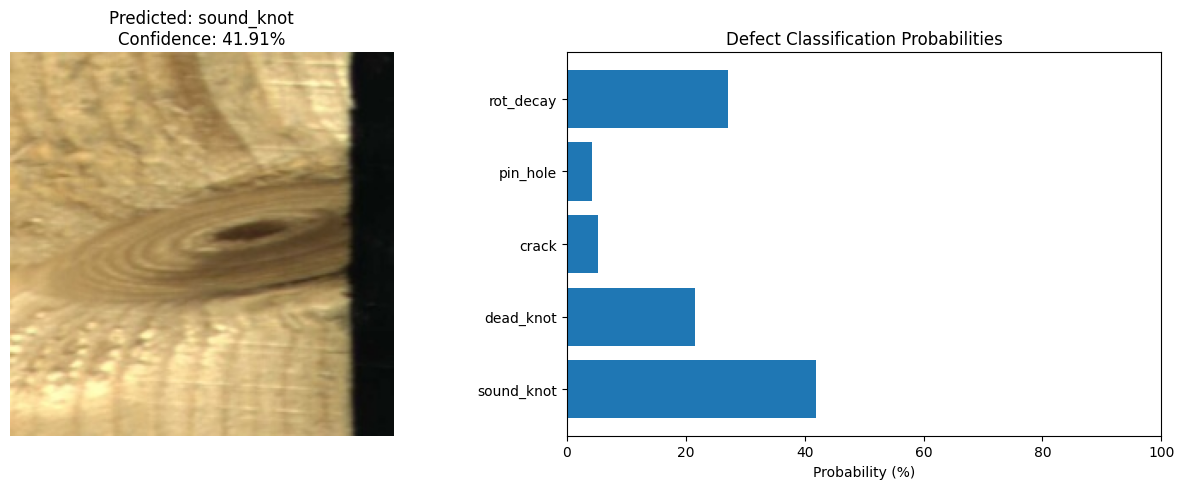


PREDICTION RESULT
----------------------------------------
Predicted class: sound_knot
Confidence: 41.91%
Sorting decision: Manual Review

All demonstration predictions completed.


In [ ]:
# ===== Cell 19: End-to-End Timber Defect Prediction =====

print("=" * 60)
print("END-TO-END PREDICTION SYSTEM")
print("=" * 60)

SORTING_RULES = {
    "sound_knot": "Grade A",
    "dead_knot": "Grade B",
    "crack": "Reject",
    "pin_hole": "Reject",
    "rot_decay": "Reject"
}

def predict_defect(image_path):

    """
    Load a timber crop and predict its defect category.

    Input:
        image_path: Path of a JPEG or other readable image.

    Output:
        Predicted class, confidence, class probabilities,
        and automated sorting decision.
    """

    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    model.eval()

    # Load and preprocess the input image.
    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_transform(
        image
    ).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():

        with torch.cuda.amp.autocast(enabled=use_amp):

            outputs = model(input_tensor)

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )[0]

    predicted_index = probabilities.argmax().item()

    predicted_class = INDEX_TO_CLASS[
        predicted_index
    ]

    confidence = probabilities[
        predicted_index
    ].item()

    if confidence < CONFIDENCE_THRESHOLD:

        decision = "Manual Review"

    else:

        decision = SORTING_RULES[predicted_class]

    # Display original image and probability chart.
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5)
    )

    axes[0].imshow(image)

    axes[0].set_title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    axes[0].axis("off")

    probability_values = probabilities.cpu().numpy() * 100

    axes[1].barh(
        CLASS_NAMES,
        probability_values
    )

    axes[1].set_xlabel("Probability (%)")
    axes[1].set_title("Defect Classification Probabilities")
    axes[1].set_xlim(0, 100)

    plt.tight_layout()
    plt.show()

    print("\nPREDICTION RESULT")
    print("-" * 40)
    print("Predicted class:", predicted_class)
    print("Confidence:", f"{confidence * 100:.2f}%")
    print("Sorting decision:", decision)

    return {
        "predicted_class": predicted_class,
        "confidence": confidence,
        "sorting_decision": decision,
        "probabilities": {
            name: float(probabilities[index].item())
            for index, name in enumerate(CLASS_NAMES)
        }
    }


# Demonstrate prediction on three unseen test images.
print("\nDEMO: THREE TEST IMAGES")

demo_samples = test_df.sample(
    n=min(3, len(test_df)),
    random_state=100
)

demo_results = []

for index, (_, record) in enumerate(demo_samples.iterrows(), 1):

    print(f"\nDEMO IMAGE {index}")

    result = predict_defect(
        record["image_path"]
    )

    demo_results.append(result)

print("\nAll demonstration predictions completed.")

In [ ]:
# ===== Cell 20: Final Summary, JSON and Project ZIP =====

print("=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)

# Collect all final metrics.
final_results = {
    "project_name": "Automated Wood Timber Surface Knot and Decay Defect Sorting System",

    "model": "MobileNetV3-Large",

    "classes": CLASS_NAMES,

    "dataset": CONFIG["dataset_name"],

    "total_images": len(dataset_df),

    "train_images": len(train_df),

    "validation_images": len(val_df),

    "test_images": len(test_df),

    "test_accuracy": float(test_accuracy),

    "macro_f1": float(macro_f1),

    "weighted_f1": float(weighted_f1),

    "gpu_mean_latency_ms": gpu_results["mean_latency_ms"],

    "gpu_p95_latency_ms": gpu_results["p95_latency_ms"],

    "gpu_fps": gpu_results["fps"],

    "cpu_mean_latency_ms": cpu_results["mean_latency_ms"],

    "cpu_p95_latency_ms": cpu_results["p95_latency_ms"],

    "cpu_fps": cpu_results["fps"],

    "model_size_mb": float(model_size_mb),

    "best_validation_accuracy": float(best_val_accuracy),

    "class_distribution": {
        name: int(crop_counts[name])
        for name in CLASS_NAMES
    },

    "sorting_simulation_boards": int(simulation_count),

    "sorting_simulation_throughput": float(throughput)
}

# Create a readable results table.
results_table = pd.DataFrame([
    {
        "Metric": "Test Accuracy",
        "Value": f"{test_accuracy * 100:.2f}%"
    },
    {
        "Metric": "Macro F1-Score",
        "Value": f"{macro_f1:.4f}"
    },
    {
        "Metric": "Weighted F1-Score",
        "Value": f"{weighted_f1:.4f}"
    },
    {
        "Metric": "GPU Mean Latency",
        "Value": (
            f"{gpu_results['mean_latency_ms']:.3f} ms"
            if gpu_results["mean_latency_ms"] is not None
            else "Unavailable"
        )
    },
    {
        "Metric": "GPU FPS",
        "Value": (
            f"{gpu_results['fps']:.2f}"
            if gpu_results["fps"] is not None
            else "Unavailable"
        )
    },
    {
        "Metric": "CPU Mean Latency",
        "Value": f"{cpu_results['mean_latency_ms']:.3f} ms"
    },
    {
        "Metric": "CPU FPS",
        "Value": f"{cpu_results['fps']:.2f}"
    },
    {
        "Metric": "Model Size",
        "Value": f"{model_size_mb:.2f} MB"
    }
])

print("\nFINAL PERFORMANCE TABLE")
print("-" * 50)

print(
    results_table.to_string(index=False)
)

# Save JSON results.
results_json_path = os.path.join(
    CONFIG["output_dir"],
    "results.json"
)

with open(
    results_json_path,
    "w"
) as file:

    json.dump(
        final_results,
        file,
        indent=4
    )

print("\nResults saved:", results_json_path)

# Create final ZIP archive.
zip_path = "/content/wood_defect_project.zip"

files_to_zip = [
    best_model_path,
    split_path,
    results_json_path
]

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in files_to_zip:

        if os.path.exists(file_path):

            zip_file.write(
                file_path,
                arcname=os.path.basename(file_path)
            )

        else:

            print("Warning: Missing file:", file_path)

print("\nZIP archive created successfully.")

print(
    "ZIP size:",
    f"{os.path.getsize(zip_path) / (1024 ** 2):.2f} MB"
)

print("\nFINAL PROJECT FILES:")

for file_path in files_to_zip:
    print(
        os.path.basename(file_path),
        "->",
        os.path.exists(file_path)
    )

# Download the ZIP to your computer.
try:

    from google.colab import files

    files.download(zip_path)

    print("\nDownload initiated successfully.")

except Exception as e:

    print("\nAutomatic download unavailable.")
    print("Your ZIP is saved at:", zip_path)
    print("You can download it from the Colab Files panel.")
    print("Error:", str(e))

print("\nPROJECT PIPELINE COMPLETED.")

FINAL PROJECT SUMMARY

FINAL PERFORMANCE TABLE
--------------------------------------------------
           Metric     Value
    Test Accuracy    72.06%
   Macro F1-Score    0.7205
Weighted F1-Score    0.7220
 GPU Mean Latency  6.409 ms
          GPU FPS    156.03
 CPU Mean Latency 26.646 ms
          CPU FPS     37.53
       Model Size  16.25 MB

Results saved: /content/wood_project/results.json

ZIP archive created successfully.
ZIP size: 15.03 MB

FINAL PROJECT FILES:
best_model.pth -> True
split.csv -> True
results.json -> True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download initiated successfully.

PROJECT PIPELINE COMPLETED.


In [ ]:
import os

for root, dirs, files_list in os.walk("/content"):
    for file in files_list:
        if file.endswith((".pth", ".pt")):
            print(os.path.join(root, file))

/content/wood_project/best_model.pth
/content/wood_project/wood_mobilenetv3_torchscript.pt


In [ ]:
from google.colab import files

files.download("/content/wood_project/best_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
class_names = [
    "sound_knot",
    "dead_knot",
    "crack",
    "pin_hole",
    "rot_decay"
]

print(class_names)

['sound_knot', 'dead_knot', 'crack', 'pin_hole', 'rot_decay']


In [ ]:
import json
from google.colab import files

class_config = {
    "class_names": class_names,
    "num_classes": len(class_names)
}

with open("/content/class_config.json", "w") as f:
    json.dump(class_config, f, indent=4)

files.download("/content/class_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model_config = {
    "architecture": "MobileNetV3_Large",
    "num_classes": len(class_names),
    "input_size": 224,
    "image_size": [224, 224],
    "pretrained": True
}

with open("/content/model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

files.download("/content/model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>